In [1]:
import numpy as np
import matplotlib.pyplot as plt
from SingleAgent import *

## Theoretical Qlearning values

In [2]:
delta_value = 0.6
epsilon_value = 0.1
P, R, T, S = 0.2, 0.8, 1, 0

In [3]:
def theoretical_qlearning_values_for_grim_trigger(P, R, T, S, delta):
    t_q11 =  P/(1-delta)
    t_q00 = R + (delta * t_q11)  
    t_q01 = T + (delta * t_q11)
    t_q10 = S + (delta * t_q11)

    return t_q00, t_q01, t_q10, t_q11

In [4]:
def theoretical_qlearning_values_for_grim_trigger_with_epsilon(P, R, T, S, delta, epsilon):
    e_t_q11 = (epsilon/2 * T + (1 - (epsilon/2)) * P) / (1-delta)
    e_t_q00 = ((1 - epsilon)* R + epsilon * S)/(1-delta)
    e_t_q01 = (1 - epsilon) * T + epsilon* P + delta * e_t_q11
    e_t_q10 = (epsilon/2 * 1 + (1 - (epsilon/2)) * P) / (1-delta)

    return e_t_q00, e_t_q01, e_t_q10, e_t_q11

In [5]:
theoretical_qlearning_values_for_grim_trigger(P, R, T, S, delta_value)

(1.1, 1.3, 0.3, 0.5)

In [6]:
theoretical_qlearning_values_for_grim_trigger_with_epsilon(P, R, T, S, delta_value, epsilon=epsilon_value)

(1.8, 1.28, 0.6, 0.6)

## Single Run

Final Q-values for Player 1:
[[18.81000847 18.81000845]
 [19.0100084  19.01000835]]
Final Q-values for Player 1 tell us that the player is Defecting
Number of collaborations: 498, Number of defections: 1075
Expected behavior: collaborate more


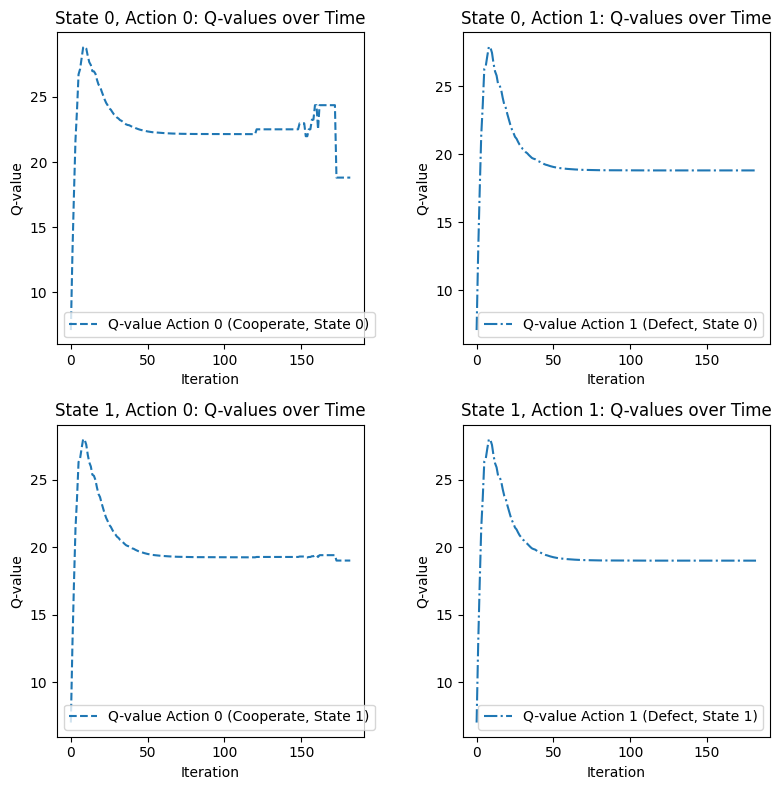

Cooperations: 498, Defections: 1075


In [20]:
# Initialize the solver with GrimTrigger_QValues
strategy = GrimTrigger_QValues()
solver = PrisonersDilemmaSolver(
    strategy=strategy,
    e_initial=0.1,
    lambda_val=0.1,
    alpha=0.1,
    delta=delta_value,
    K=500,
    M=10,
    e_decay=1,
    random_uniform=True,
    verbose=True
)

# Run the solver
cooperations, defections, q1_history, mean_q_values, grim_trigger_count_dict = solver.run()

# Check results
print(f"Cooperations: {cooperations}, Defections: {defections}")


#### Added a new feature for counting how many times the player learns how to play GT for each sample. In SingleAgent.py look at the function "check_grim_trigger"

In [21]:
pd.Series(grim_trigger_count_dict)

0    153
1      0
2      0
3      0
4    165
5      0
6      0
7      0
8    156
9      0
dtype: int64

## Multiple Random Seed

In [ ]:
seeds = random.sample(range(1, 10000), 10)

all_cooperations = []
all_defections = []

for seed in seeds:
    random.seed(seed)
    strategy = GrimTrigger_QValues()  # Or use TitForTat()
    solver = PrisonersDilemmaSolver(strategy, e_initial=epsilon_value, 
                                    lambda_val=0.1, 
                                    alpha=0.05, 
                                    delta=0.9, 
                                    K=100, 
                                    M=10, 
                                    e_decay=0.95, 
                                    verbose=False, plotting = False)
    
    cooperations, defections, q = solver.run()
    all_cooperations.append(cooperations)
    all_defections.append(defections)

all_cooperations = np.array(all_cooperations)
all_defections = np.array(all_defections)

mean_cooperations = np.mean(all_cooperations)
mean_defections = np.mean(all_defections)

print(f"Mean cooperations: {mean_cooperations}")
print(f"Mean defections: {mean_defections}")


Number of collaborations: 58, Number of defections: 1365
Expected behavior: defect more
Number of collaborations: 149, Number of defections: 1293
Expected behavior: defect more
Number of collaborations: 143, Number of defections: 1344
Expected behavior: defect more
Number of collaborations: 127, Number of defections: 1310
Expected behavior: defect more
Number of collaborations: 132, Number of defections: 1324
Expected behavior: defect more
Number of collaborations: 78, Number of defections: 1345
Expected behavior: defect more
Number of collaborations: 67, Number of defections: 1338
Expected behavior: defect more
Number of collaborations: 59, Number of defections: 1376
Expected behavior: defect more
Number of collaborations: 92, Number of defections: 1277
Expected behavior: defect more
Number of collaborations: 27, Number of defections: 1391
Expected behavior: defect more
Mean cooperations: 93.2
Mean defections: 1336.3


## Critical Value of delta

In [7]:
## Should this be changed, putting how many times it learns to play gt instead or number of cooperations?

In [11]:
def analyze_critical_delta(strategy, e_initial, lambda_val, alpha, delta_range, K, M, e_decay, random_uniform=True):
    """
    Analyzes the critical value of delta for which the agent begins cooperating against the Grim Trigger strategy.
    
    Parameters:
        strategy: The opponent strategy (e.g., GrimTrigger).
        e_initial: Initial exploration rate for Q-learning.
        lambda_val: Eligibility decay parameter.
        alpha: Learning rate for Q-learning.
        delta_range: Tuple specifying the range of delta (min, max, step).
        K: Number of iterations per episode.
        M: Number of episodes to train.
        e_decay: Decay rate for exploration rate.
        random_uniform: Whether to initialize Q-values randomly.
    
    Returns:
        A plot of cooperation ratio vs. delta.
    """
    deltas = np.arange(delta_range[0], delta_range[1], delta_range[2])
    cooperation_ratios = []

    for delta in deltas:
        print(f"Running for delta = {delta:.2f}...")  # Verbose output to track progress
        # Initialize the solver for the given delta
        solver = PrisonersDilemmaSolver(
            strategy=strategy,
            e_initial=e_initial,
            lambda_val=lambda_val,
            alpha=alpha,
            delta=delta,
            K=K,
            M=M,
            e_decay=e_decay,
            random_uniform=random_uniform,
            verbose=False,
            plotting=False  # Suppress plotting for individual runs
        )
        # Run the solver and collect results
        cooperations, defections, _, _, checkGT= solver.run()

        # Calculate cooperation ratio
        total_actions = cooperations + defections
        cooperation_ratio = cooperations / total_actions if total_actions > 0 else 0
        cooperation_ratios.append(cooperation_ratio)

    # Plot the cooperation ratio as a function of delta
    plt.figure(figsize=(10, 6))
    plt.plot(deltas, cooperation_ratios, marker='o', linestyle='-', label="Cooperation Ratio")
    plt.axhline(y=0.5, color='r', linestyle='--', label="50% Cooperation Threshold")
    plt.xlabel("Delta (Discount Factor)")
    plt.ylabel("Cooperation Ratio")
    plt.title("Cooperation Ratio vs. Delta in Prisoner's Dilemma")
    plt.legend()
    plt.grid()
    plt.show()

    # Return raw data for further analysis if needed
    return deltas, cooperation_ratios


In [ ]:
# Define parameters for the experiment
strategy = GrimTrigger_QValues()
e_initial = epsilon_value
lambda_val = 0.1
alpha = 0.1
delta_range =  (0.85, 1, 0.05)# Analyze delta from 0.5 to 1.0 in steps of 0.01
K = 500 # Number of iterations per episode
M = 1  # Number of episodes
e_decay = 1  # Decay rate for exploration
random_uniform = False  # Initialize Q-values randomly

# Run the analysis
deltas, cooperation_ratios = analyze_critical_delta(
    strategy=strategy,
    e_initial=e_initial,
    lambda_val=lambda_val,
    alpha=alpha,
    delta_range=delta_range,
    K=K,
    M=M,
    e_decay=e_decay,
    random_uniform=random_uniform
)


Running for delta = 0.85...
Number of collaborations: 0, Number of defections: 118
Expected behavior: defect more
Running for delta = 0.90...
Number of collaborations: 0, Number of defections: 131
Expected behavior: collaborate more
Running for delta = 0.95...
Number of collaborations: 1, Number of defections: 132
Expected behavior: collaborate more
Running for delta = 1.00...
